# **MMME4125 2026/2027 Coursework**

**Student Name:** Harrison Coleman

**Student ID:** 20447032

# **Project Description**

In this coursework, you will analise historical data and build your own machine learning pipeline demonstrating your knowledge on data exploration, data preparation and machine learning model development to solve a prediction or classification task  of an engineering domain problem.

**Dataset:** You will select a data set from a range of data sets provided in this module's Moodle page.

**Overall task:** Utilising your selected data set, you will build at least two models of your choice either for regression or classification (depending on the data set you selected) from the ones covered during lectures (e.g. NN, Decision Trees, Randon Forest, CNN to name a few examples). Employ appropriate methods from the pandas, matplotlib, keras and sklearn libraries to analyse and process the dataset and for building predictive models.

**Note:** You must use only pandas, numpy, matplotlib, keras and sklearn or any other specific library that was covered during class for example for data augmentation. Do not use other libraries or external packages. Use of such packages may receive zero credit for the affected parts. 

**Format:** Use this Jupyter Notebook as a template to write your report/answers to questions in Markdown cells, supported by your source code in Code cells.

The project (and this notebook) are structured in three main tasks:

**(Task 1)** -  Data set selection & data exploration : Once you select the data set you will carry out an initial Exploratory Data Analysis (EDA). Some data sets might be too large, containing multiple features or measurements of multiple variables. As you explore your data, you will make a decision of which sub set of your data you will use for your prediction/classification task. **You will then discuss this decision with your lab tutor (you will book a slot for this during lab hours) and get feedback**. As it will be indicated later in this notebook, you will add as markdown your analysis of the EDA results, the feedback provided by the tutor and how this has been taken into account to move to the next task. 

**(Task 2)** - Data preparation : with your chosen dataset (or subset), you will carry out the data preparation. This will include data visualisation (e.g. patterns, class imbalance, outliers), dealing with any missing values, outlier handling, scaling/normalisation, feature extraction, data reduction/augmentation, creating of training,validaton and test sets). 

**(Task 3)** - Model Development & Metrics Analysis : once your data set is ready, select two ML approaches from the ones covered during the lectures and discuss your selection with your lab tutor (**you will need to book a second lab slot for this and get feedback**). You will add in a Markdown cell your rationale for chosing such models, providing details of the feedback provided by the lab tutor and how it was used to move forward. Additional rationale for the specific hyper-parameters should also be included. Implementation should be added in a Code cell with appropriate code comments. Appropriate metrics for the model used should be implemented and presented (e.g. RMSE, Precision, Recall, F-Score, confusion matrix). You may want to try multiple hyper parameters to understand how the model behaves and if further iprovement can be obtained. In a Markdown cell, please explain the results obtained on both models and present a discussion of results. This discussion should include your insights on how model design/hyper-parameters affected the quality of the results.


Ensure your code produces the corresponding plots or results addressing the questions. Rename this .ipynb file to 202627_MMME4125_cw_XXX.ipynb, where XXX is your username (e.g., psxyz), and submit it to Moodle by **DATE**

**Marks**: The coursework is worth a total of 100 marks (accounting for 70% of the module grade). Marks will be awarded based on your understanding of machine learning theories, the informativeness and presentation of your code, visualisations, results (e.g., code comments, necessary labels in plots) and analysis, evidence of feedback and how it was addressed, your self-learning ability in solving the specific problem, and how succinct and clear your report writing is.

In [2]:
# You can change the import statements as you wish, but you should not use any library beyond pandas, numpy, matplotlib, and sklearn.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

In [3]:
import pandas as pd

# Load the CSV dataset
file_path = "HEA Phase DataSet v1d.csv"

df = pd.read_csv(file_path,encoding="cp1252")
display(df.head())
df.shape

,Alloy ID,Alloy,Al,Co,Cr,Fe,Ni,Cu,Mn,Ti,...,Quenching,HPR,Microstructure_,Multiphase,IM_Structure,Microstructure,Phases,References,Unnamed: 51,Unnamed: 52
0,Alloy 0000,Al0.5NbTaTiV,0.111111,0.0,0.0,0.0,0.0,0.0,0.0,0.222222,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.1016/j.proeng.2012.03.043,NaN,NaN
1,Alloy 0001,Al0.75MoNbTiV,0.157895,0.0,0.0,0.0,0.0,0.0,0.0,0.210526,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.3390/e16020870,NaN,NaN
2,Alloy 0002,Al0.25MoNbTiV,0.058824,0.0,0.0,0.0,0.0,0.0,0.0,0.235294,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.3390/e16020870,NaN,NaN
3,Alloy 0003,Al0.25NbTaTiV,0.058824,0.0,0.0,0.0,0.0,0.0,0.0,0.235294,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.1016/j.proeng.2012.03.043,NaN,NaN
4,Alloy 0004,Al0.2MoTaTiV,0.047619,0.0,0.0,0.0,0.0,0.0,0.0,0.238095,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.4028/www.scientific.net/MSF.898.638,NaN,NaN


(1361, 53)

<div class="alert alert-success" style="text-align:left;">
<h2>Task 1. Dataset Selection & Exploratory Data Analysis<span style="float:right;">[25 marks]</span></h2></div>

### Task 1a. <span style="color:red">(10 marks)</span>

Start by introducing the engineering problem that you will be addressing, what the current industrial practice is to solve this problem and why ML is a good approach to solve it (3 marks). Explain the data set you have selected by providing details on what each variable represents, if you suspect there are any likely measurement problems, if there are any variables that could introduce leakage and if any mechanical principles may provide initial plausible relationships across these variables (5 marks).  Finally explain why this is a regression or a classification task (2 marks)



*The Problem*

High entropy alloys (HEAs) are a class of materials that contain multiple principle elements in nearly equal atomic proportions. Normally this is 5 or more principle elements. This is in contrast with traditional, typical metal alloys which are comprised of one or two major components with smaller amounts of other elements. The effect of the large number of principle alloying elements is the production of unique microstructures and resulting desireable mechanical properties. HEAs can offer high temperature strengths (exceeding those of nickel superalloys), high wear, corrosion and oxidation resistance, good high temperature stability, and high radiation resistance. It is therefore clear to see how application of these alloys could be beneficial in a variety of engineering applications such as jet engine turbine blades or in the core of nuclear reactors.

The phase that an HEA forms largely decides its properties. Due to the large number of principle elements, there are millions of potential combinations, all with differning mechanical properties. The main method used in industry to produce differnet HEAs is experimental trail and error, which is time-consuming and costly. Other prediction methods such as CALPHAD modelling and empirical rules of thumb can run more quickly, but are often less accurate due to data extrapolation or assumptions. Ultimately, discovery of HEAs is limited by the speed of experimental research work.

Machine Learning (ML) provides a desirable solution to this bottleneck. It can rapidly screen through the very large number of candidate alloys and analyse the complex relationships between contributing factors. The model could then output the most promising ones for experiemental testing, cutting the costs of alloy discovery considerably.

*The Data*

The data is a .csv file of dimensions (1361,53). There are 1360 data entries and a header row, covering 53 variables. There are 3 identifier columns: "Alloy ID" - the numerical alloy identifier, "Alloy" - the Alloy's name, and "References" which contains the DOI of the source paper for that datapoint. There are 25 columns for composition (df.iloc[:,2:27]), which each contain a number between 0 and 1, denoting the atomic fraction of each element. Num_of_Elem counts how many elements are present in the alloy. Columns 28-36 (df.iloc[:,28:37]) are calculated parameters, likely worked out from the composition with standard formulas.

To be continued...

very clearly a classification task

### Task 1b. <span style="color:red">(5 marks)</span>

Select a subset of the data to be visualised. Include a rationale for inspecting this particular subset of data (2 mark). Produce at least 3 plots (1 mark each) to visualise patterns, distribution, class imbalance, outliers and correlations. The types of plots you use will  be determined by the type of data you are handling. These plots should be informative of the next steps you will carry out during data preparation.

In [ ]:
df = df.dropna(subset=['Phases'])          # remove the empty row at the end using column 'phases' as the check

elements = df.columns[2:27].tolist()         # the 25 element composition columns
params = df.columns[27:37].tolist()         # gathers the 10 calculated parameter column names
classes = ['BCC_SS', 'FCC_SS', 'FCC_PLUS_BCC', 'Im']    # 4 phase class names typed out for nice plotting later

df_sub = df[elements + params + ['Phases']]    # Creates the data subset, consiting of calculated parameters and phase of the alloy
print(df_sub.shape)                         # check it should be (1360, 36)
df_sub[params].describe() # summary of calculated parameters (composition excluded due to size and sparcity)



(1360, 36)


,Num_of_Elem,Density_calc,dHmix,dSmix,dGmix,Tm,n.Para,Atom.Size.Diff,Elect.Diff,VEC
count,1360.000000,1355.000000,1360.000000,1360.000000,1360.000000,1360.000000,1359.000000,1360.000000,1360.000000,1360.000000
mean,4.958088,7.869265,-6.599280,12.542192,474.888889,1823.725359,9.146608,4.414770,0.159028,6.537999
std,0.831061,1.518332,6.601809,1.734308,111.792702,430.135657,21.810314,2.291318,0.225247,1.660303
min,2.000000,2.660000,-39.450229,3.466072,171.460661,646.934672,0.559007,0.168046,0.015000,3.161339
25%,5.000000,7.069326,-10.960000,11.530000,387.096884,1489.329417,2.090463,3.262142,0.110000,4.600000
50%,5.000000,7.871765,-4.890000,13.145944,467.623384,1801.200000,4.654402,4.429916,0.122434,7.200000
75%,5.000000,8.293963,-2.696078,13.380000,548.685324,2111.996306,8.540000,5.655462,0.147521,8.000000
max,7.000000,13.640000,4.160000,16.179196,825.650392,3157.750000,279.277101,19.059548,3.920000,9.500000


*Subset Rationale*

The dataset is small (1361,53) and expensive to produce due to the nature of the experimental procedure. Every observation is a seperately made and characterised alloy and is therfore precious and should be kept in the dataset if possible. There is no reason to sample the dataset any furhter for the purposes of computing, as it is easy to work with and plot as a whole. The dataset is already small, with the smallest phase class (FCC+BCC) having only 102 alloys. Cutting rows would leave even fewer to look at and make it harder to see any patterns. Therefore it is best to keep all the data rows, except the last one, which is empty and contains no information for the model.

The columns for the subset were chosen based on relevence to the problem. The calculated parameter columns, columns[27:37], are the quantities that metallurgy theory uses to predict which phase an alloy forms, for example the average number of valence electrons (VEC) affects which crystal structure is the most stable. They are therefore critical to testing whether the expected relationships from theory show up obviously in the data. The composition columns, columns[2:27], show the coverage of the alloy data. Counting how many alloys contain each element shows which elements the dataset covers the influence of well and which elements have insufficent coverage. A model can't be trusted for alloys built on elements it has barely seen. The "Phases" column was included as it is the target for the ML model. Evey plot is more useful for cisualtion when split by phases, as it allows an initial analysis of data trends. All the selected data columns are numerical and continuous so can be easily plotted by histograms, boxplots, correlation heatmaps and scattter plots.

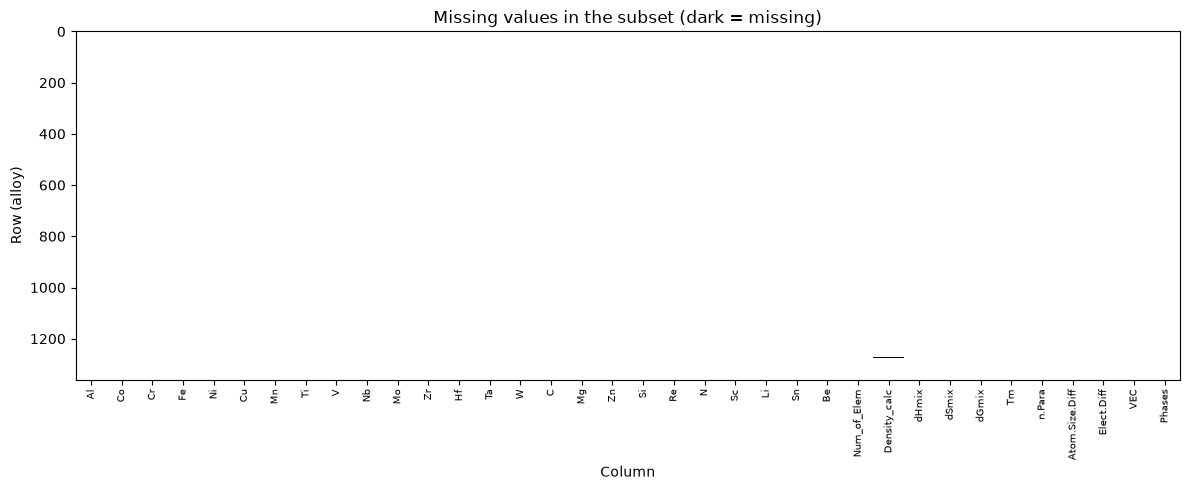

Density_calc    5
n.Para          1
dtype: int64
Total missing: 6 of 48960 values
                Alloy   Phases
990               CoNi  FCC_SS
1272          TiZrNbTa  BCC_SS
1273   (TiZrNbTa)95Mo5  BCC_SS
1274  (TiZrNbTa)90Mo10  BCC_SS
1275  (TiZrNbTa)85Mo15  BCC_SS
1276        MoNbTaTiZr  BCC_SS


In [5]:
# Plot 1 - Missing values in the subset
plt.figure(figsize=(12, 5))
plt.imshow(df_sub.isna(), aspect='auto', cmap='Greys', interpolation='none')
plt.xticks(range(len(df_sub.columns)), df_sub.columns, rotation=90, fontsize=7)
plt.xlabel('Column')
plt.ylabel('Row (alloy)')
plt.title('Missing values in the subset (dark = missing)')
plt.tight_layout()
plt.show()
# This plots a heatmap showig missing values, although due to the size of the dataset and limits on screen resolution, it may not show individual values

# Produce numerical outputs of missing data and output row number
n_missing = df_sub.isna().sum()
print(n_missing[n_missing > 0])                                   # which columns have gaps
print('Total missing:', n_missing.sum(), 'of', df_sub.size, 'values')
print(df.loc[df_sub.isna().any(axis=1), ['Alloy ', 'Phases']])   # which alloys they are
# This outputs what and where the missing data vlaues are, useful for later data manipulation

Phases
Im              34.0
BCC_SS          32.4
FCC_SS          26.0
FCC_PLUS_BCC     7.5
Name: count, dtype: float64


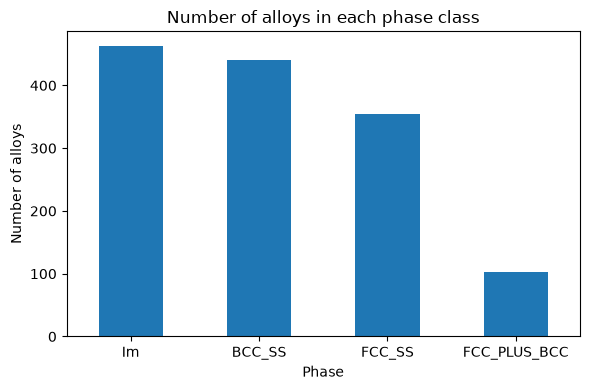

In [6]:
# Plot 2 - Class imbalance
counts = df_sub['Phases'].value_counts() # counts how many times each label appears
print((counts / counts.sum() * 100).round(1))   # converts counts to percentages and prints

plt.figure(figsize=(6, 4))
counts.plot(kind='bar')
plt.title('Number of alloys in each phase class')
plt.xlabel('Phase')
plt.ylabel('Number of alloys')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
# Produces a bar graph 


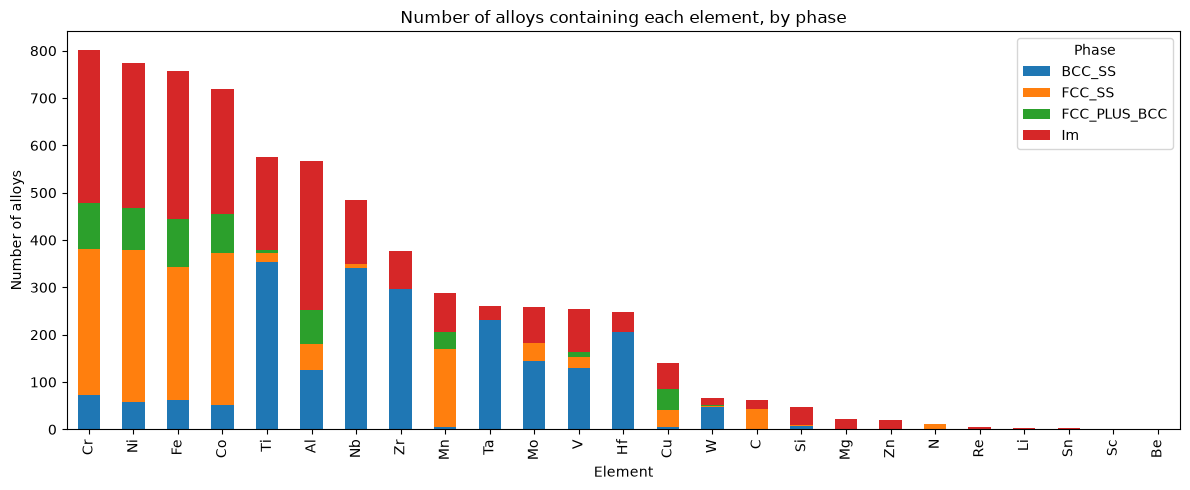

Cr    801
Ni    774
Fe    757
Co    720
Ti    575
Al    567
Nb    485
Zr    377
Mn    288
Ta    261
Mo    258
V     254
Hf    247
Cu    140
W      67
C      63
Si     47
Mg     21
Zn     20
N      12
Re      4
Li      3
Sn      2
Sc      0
Be      0
dtype: int64
Phases  BCC_SS  FCC_SS  FCC_PLUS_BCC     Im
Cr         9.0    39.0          12.0   40.0
Ni         7.0    41.0          11.0   40.0
Fe         8.0    37.0          13.0   41.0
Co         7.0    44.0          12.0   37.0
Ti        62.0     3.0           1.0   34.0
Al        22.0    10.0          13.0   56.0
Nb        70.0     2.0           0.0   28.0
Zr        79.0     0.0           0.0   21.0
Mn         2.0    57.0          12.0   29.0
Ta        89.0     0.0           0.0   11.0
Mo        56.0    14.0           0.0   29.0
V         51.0     9.0           4.0   36.0
Hf        83.0     0.0           0.0   17.0
Cu         4.0    24.0          33.0   39.0
W         70.0     4.0           1.0   24.0
C          0.0    70.0           

In [7]:
# Plot 3 - Number of alloys containing each elements
contains = df_sub[elements] > 0                       # True where the element is present
element_counts = contains.groupby(df_sub['Phases']).sum().T   # splits the alloys into the four phase groups, sums no. alloys per group and transposes table
element_counts = element_counts[classes]                              # use consistent class order
element_counts = element_counts.loc[element_counts.sum(axis=1).sort_values(ascending=False).index]   # Sorts from largest to smallest

element_counts.plot(kind='bar', stacked=True, figsize=(12, 5)) # Draws stacked bar chart
# plt.axhline(30, color='grey', linestyle='--', label='30 alloys')   # draws a horizontal line to denote a lower bound on number of alloys in dataset for it to be useful
plt.title('Number of alloys containing each element, by phase')
plt.xlabel('Element')
plt.ylabel('Number of alloys')
plt.legend(title='Phase')
plt.tight_layout()
plt.show()
# Produces a stacked bar chart of how many alloys contain each element, allows visualisation of element distribution

print(element_counts.sum(axis=1))                                          # numerical representation of height of each full bar
print((element_counts.div(element_counts.sum(axis=1), axis=0) * 100).round(0))   # numerical percentage representaion of the phase split of each element

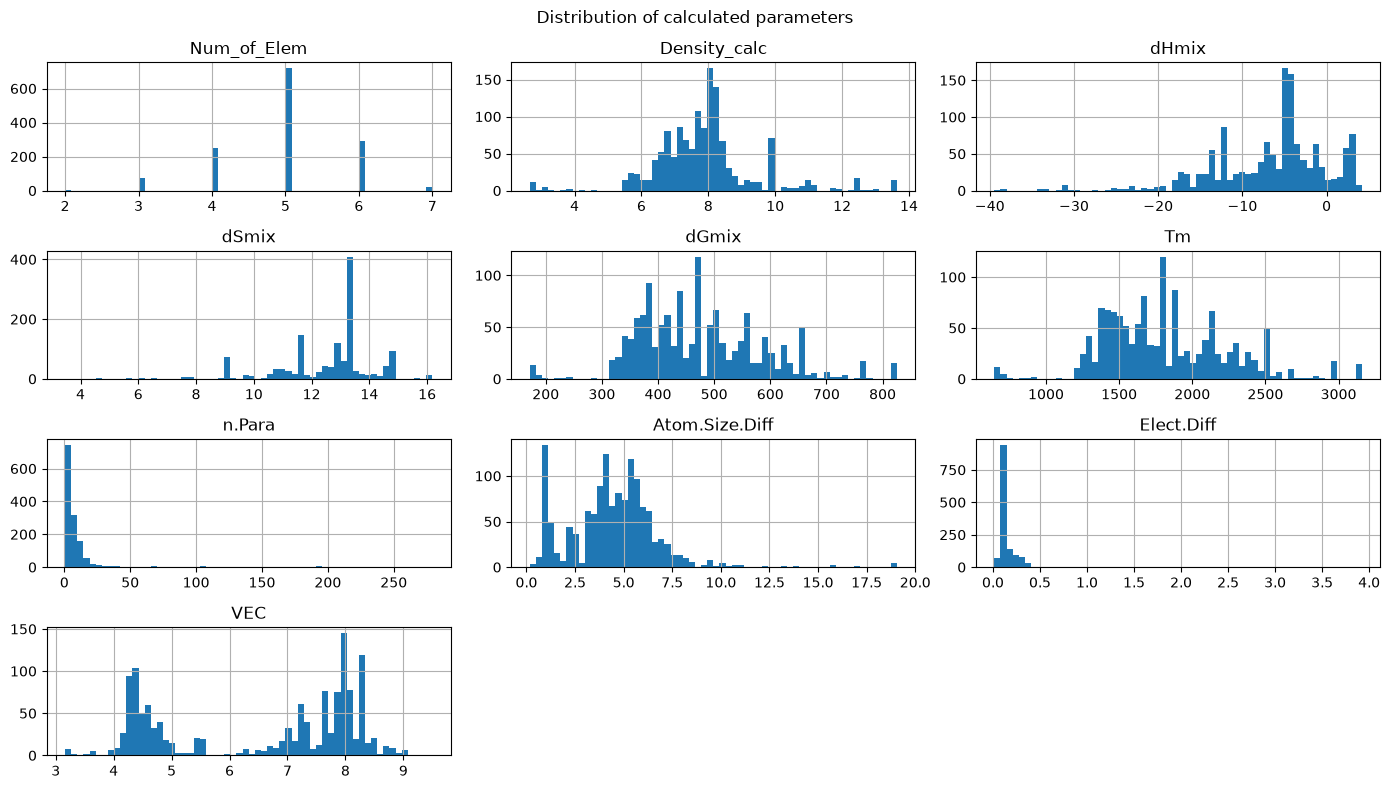

In [ ]:
# Plot 4 - Distribution of each calculated parameter for all alloys
hist_res=60 # sets histogram resolution (higher equals smaller column width)
df_sub[params].hist(bins=hist_res, figsize=(14, 8)) # selects the 10 calculated parameters and plots a grid of historgrams for each
plt.suptitle('Distribution of calculated parameters')
plt.tight_layout()
plt.show()
# Plots each calculated parameter for each alloy on a histogram to show distribution and odd values
# Allows for good data visualisation

C:\Users\LLR User\AppData\Local\Temp\ipykernel_24532\3708913167.py:3: UserWarning: When passing multiple axes, sharex and sharey are ignored. These settings must be specified when creating axes.
  df_sub.boxplot(column=params, by='Phases', ax=axes.flatten(), rot=45, grid=False)


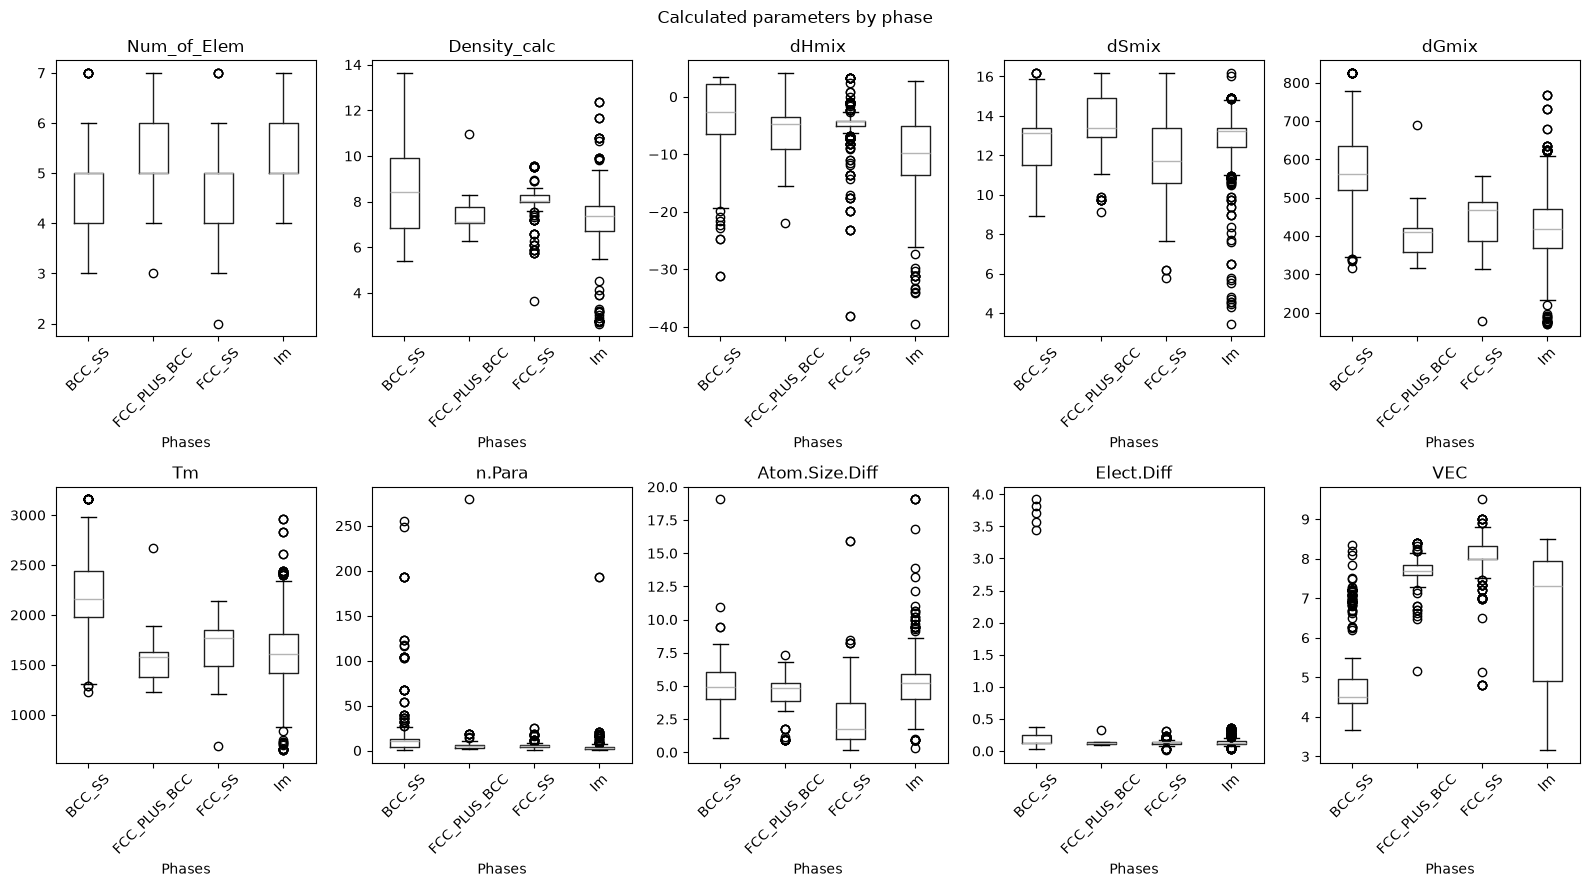

Phases           BCC_SS  FCC_PLUS_BCC   FCC_SS       Im
Num_of_Elem        5.00          5.00     5.00     5.00
Density_calc       8.43          7.12     8.03     7.39
dHmix             -2.60         -4.78    -4.29    -9.80
dSmix             13.15         13.38    11.69    13.25
dGmix            562.44        411.49   466.78   418.15
Tm              2162.97       1574.75  1769.00  1606.08
n.Para            10.75          5.08     5.06     2.38
Atom.Size.Diff     4.92          4.82     1.77     5.25
Elect.Diff         0.12          0.12     0.14     0.12
VEC                4.50          7.70     8.00     7.31


In [ ]:
# Plot 5 - Box plot of each parameter, split by phase
fig, axes = plt.subplots(2, 5, figsize=(16, 9))
df_sub.boxplot(column=params, by='Phases', ax=axes.flatten(), rot=45, grid=False)
plt.suptitle("Calculated parameters by phase")
plt.tight_layout()
plt.show()

print(df_sub.groupby('Phases')[params].median().round(2).T)   # prints median of parameter per class

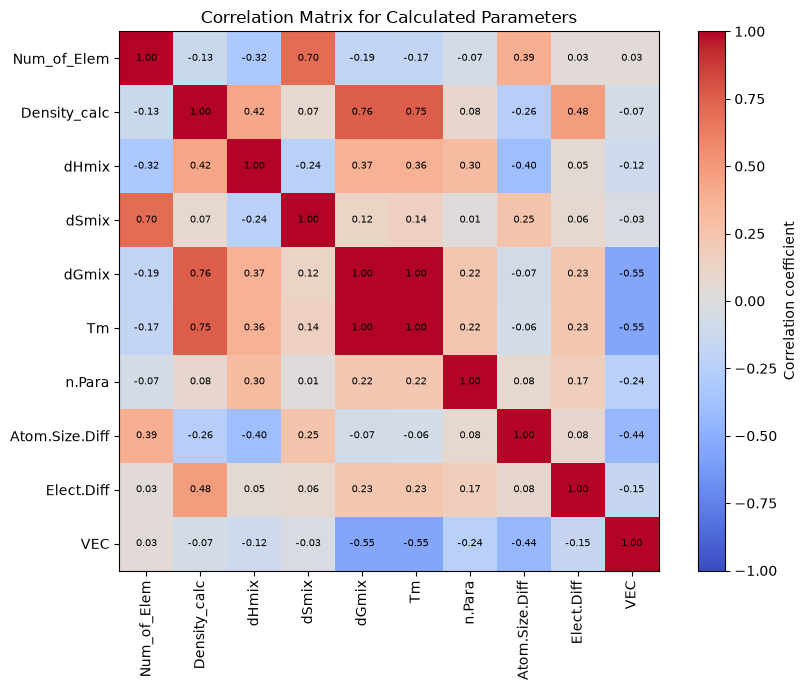

In [ ]:
# Plot 6 - Correlation matrix of the calculated parameters

corr = df_sub[params].corr() # Calculates Pearson correlation between each pair of the calculated parameters

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation coefficient')
plt.xticks(range(len(params)), params, rotation=90)
plt.yticks(range(len(params)), params)
for i in range(len(params)):
    for j in range(len(params)):
        plt.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.title('Correlation Matrix for Calculated Parameters')
plt.tight_layout()
plt.show()

# Produces a labelled Pearson correlation matrix for the calculated values
# Highly correlated values contain the same data, useful for later

In [ ]:
# Extra Observation - Duplicate alloy compositions
comp = df_sub[elements].round(4) # takes element compositions and rounds to ignore floting point errors
print('Rows:', len(df_sub), '| Unique compositions:', len(comp.drop_duplicates())) # counts number of unique element compositions compared to total

Rows: 1360 | Unique compositions: 433


### Task 1c. <span style="color:red">(10 marks)</span>

-By using your plots from 1b, provide an analysis of the data (e.g. observed patterns, correlations, potential best predictors) and briefly explain how each code snippet supports your evaluation of potential issues with the data (5 marks).

-Once you have done your analysis/insights you should discuss this with your lab tutor (you need to book a slot in lab hours for this), capture that feedback, report it here as well as a reflection of how the feedback informs the next steps of data processing (5 marks).

*Task 1c. Write here your analysis/insights of the EDA, the feedback you received from your tutor and your reflection of how the feedback influences your next steps on the data processing.*

*Exploratory Data Analysis Insights*

Question for tutor: 
What does it mean by code snippets?
Should I calculate skew for Plot 4?
Boxplot by phase or just boxplot for whole data set?

Plot 1 - Missing values
The chosen subset is almost complete, with only 6 missing values out of the 48,690 total (0.12% of the dataset). The missing values heatmap is almost entirely blank, which confirms that the subset choice has avoided any gappy data. Out of the 6 missing values, 5 entries are missing in the 'Density_calc' column and the other 1 missing entry is in the 'n.Para column'. However, the plot may be misleading due to limitations on screen resolution. It is not immediately obvious the quantity/location of all the missing data, on my laptop I only see one missing data line, which is in the 'Density_Calc' column, this is because the 5 missing datapoints are bunched together and my screen is therefore able to display it as a line of pixels. The missing data in the 'n.Para' columm is invisible to me. It is therefore important to output the missing data numerically with a print command. It is worth noting that the 5 missing densities are all from the TiZRNbTa family. It is possible that these alloys had measurement errors/difficulties and maybe should be excluded from the set. The alloy with the missing 'n.Para' is alloy CoNi, whic only has two alloying elements and can't really be considered a HEA by standard definitions. The total amount of missing data is less than 5%, therfore removing these incomplete rows is acceptable and will be carried out later.

Plot 2 - Class Imbalance
The class balance is as follows: Im 463 (34.0%), BCC 441 (32.4%), FCC 354 (26.0%), FCC+BCC 102 (7.5%). Im, BCC, and FCC classes are fairly evenly represented, but the FCC+BCC class is a clear minority class and therefore this is an unbalanced dataset and this needs to be addressed before training the model. This is because a model that is trained on this data subset could largely ignore the class, but still score well in testing, as it deosn't have much weight in the dataset. The model would not be able to predict properties of the minority class well. A stratified split for each set (training, validation, and testing) would ensure each set contains the representative class mix, as opposed to the variations that could occur in a random split. Undersampling is not applicable to this problem as it would throw away 70% of the data, without actually improving the prediction of the minority class. SMOTE oversampling could be used on the training set to try and alleviate this unbalance also.

Plot 3 - Element Coverage
Coverage is very uneven, elements such as Re, Li, and Sn are present in 4, 3 and 2 alloys respectively. Elements Sc and Be do not appear in any alloys at all. The model can only learn from the data it is given, so for elements it has very few examples of it won't be able to predict well. The model should not be trusted to predict alloys using elements that are outside the well covered region. It can be shown from the plot that some elements are strongly linked to one phase, for example Ta, which are 89% BCC phase, and Zr which are 79% BCC. The columns Sc and Be should be cut from the dataset as they carry no information. The inclusion of alloys in the final dataset that contain very rare elements should be considered carefully.

Plot 4 - Parameter distributions
n.Para and Elect.Diff are very skewed, dHmix and dSmix are skewed in the opposite direction. Most of these parameters are not distributed normally. The range of values these parameters can take is large, but many have very high concentrations in a single region, for example, n.Para. Overall these parameters do not lend themselves well for normalisation and standardisation, due to the outliers and lack of normal distributions. Robust scaling, using median and IQR is likely the optimal scaling method as it is meant for datasets with meaningful outliers which you cannot remove. Models based off of methods that aren't influenced much by scaling could be applicable, such as random forest.

Plot 5 - Box plot of parameters
Elec.Diff extreme outlier values look like they could be calculation or measurement errors
Most other outliers look like they could be genuine anomalies
Z score is not a good approach to check for outliers as it is meant for normally distributed data, which this is not. 

Plot 6 - Correlation matrix


<div class="alert alert-success" style="text-align:left;">
<h2>Task 2. Data Preparation<span style="float:right;">[40 marks]</span></h2></div>

### <span style="color:red">IMPORTANT NOTE: </span> 
This the beginning of your ML building pipeline. All transformations that happen to the data from here onwards may be stateless or stateful. Make a concious decision at which step of the entire process you need to split your data set into training, validation and test set. **Add an additional Code cell** for data splitting when you think it is reasonable to do so as well as **add a Markdown cell** to explain why the data set is splitted at this point of the ML pipeline and the impact data transformation operations might have on the validity of the model if the splitting is not carried out beforehand. You should also justify your train-validation-test splitting stategy.
### <span style="color:red">(8 marks) </span>

### Task 2a. Data Cleaning <span style="color:red">(7 marks)</span>
Using the libraries specificied at the top of the notebook or any other one covered in class, start cleaning your data by handling missing values, handling any duplicates and deal with outliers. Justify your methods.

*Task 2a. Add your justification here*

In [ ]:
# Task 2a. Add your code here

### Task 2b. Data Transformation <span style="color:red">(5 marks)</span>
Perform any necessary normalisation and encoding of categorical variables. Please explain why this step is necessary when building a predictive model and justify the method used.

In [ ]:
# Task 2b. Add your code here

*Task 2b. Add your explanation here*

### Task 2c. Data Reduction/Augmentation  <span style="color:red">(10 marks)</span>

Based on your data set implement either data reduction or data augmentation depending on the needs of the problem and data (5 marks). Explain why data reduction or data augmentation is necessary in the context of your engineering problem and the data set you selected as well as justify the methods used (5 marks). One thing to note is that depending on your data set, data reduction might have to be done after Task 2d Feature Engineering, so make sure you apply these two steps (Task 2c and Task 2d) in the correct order according to your data. 

**Note**: If you do have to do 2d before 2c, then just make sure your code is in the correct order in the code cells below.

In [ ]:
# Task 2c. Add your code here

*Task 2c. Add your explanation and justification here*

### Task 2d. Feature Engineering   <span style="color:red">(10 marks)</span>

An important aspect of machine learning is understanding the feature space and shaping it before training. That is, preprocessing or reshaping the data in a way that provides more relevant information and an easier job for the regressor or classifier.

Perform any feature engineering that you might think it is ideal for the type of task you are aiming (4 marks). This could include statistical features, rolling window statistics,  frequency analysis (FFT) or any others covered in lectures. 

If either you are going to work directly with the raw data, or you will be engineering features, justify why this is the case in the context of the engineering problem you are trying to solve, justifying any specific features used (3 marks). In the case of raw data, perform any additional transformation that would be needed to work with this raw data directly. 

Assess whether all data is ready for model building. If not, complete the preparation of a model-ready dataframe from your cleaned dataset. More specifically, make sure to assess whether all predictors in your prepared dataframe are directly suitable for the machine learning task, state why this is the case  and state what(if anything) still needs processing, and process / make the necessary adjustment in the data accordingly (3 marks).

In [ ]:
# Task 2c. Add your code here

Task 2c. Add your explanations/justifications here

<div class="alert alert-success" style="text-align:left;">
<h2>Task 3. ML Model Building<span style="float:right;">[35 marks]</span></h2></div>

### Task 3a. Building a base  model <span style="color:red">(10 marks)</span>

Now, after meeting your tutor for the second time to discuss your preliminary model selection and reasons for such method (you need to book again a slot during your lab for this) select and build a baseline model from scratch (e.g. define architecture in the case of NN) to predict or classify according to your problem using the preprocessed dataset. 

- Train the model and report **three different** evaluation metrics (3 marks).
- Reflecting from  your tutor feedback, explain how this feedback influenced the ML model selected, why is it appropriate for the task? why the hyper-parameters used? (4 marks)
- For each metric, explain (in a single short sentence) why it is relevant and whether the observed value suggests sensible predictions/classifications, i.e. what the values within the metric mean (3 marks). 

In [ ]:
#Add your code here

Add your justification for metrics here and what the results obtained mean.

### Task 3b. Hyper-parameter exploration <span style="color:red">(10 marks)</span>

You have now build a base model, with some initial results. It is now your task to experiment with hyper-parameters (5 marks) to see if you can improve the quality of your results. It is up to you how you approach this process, but you need to justify (5 marks ) the approach you are taking and discuss the results. What effect is having the changes you are doing to the approach?

In [ ]:
#perform your different hyper-parameter optimisation/changes here

Add here your justification for how you are approaching the hyper-parameter tuning  and discuss your results.

### Task 3c. Additional Models and Final Analysis <span style="color:red">(15 marks)</span>

Implement at least one more method of your choice.Report model quality with clear evidence (metrics). Compare with the baseline using supportive tables or visualisations (4 marks), and discuss the strengths and limitations of each (3 marks). Finally, provide a discussion (8 marks) on:

Why this type of model and would you deploy it in a real environment? why?

Under what operating conditions would you not trust it? how could you improve it?

What additional sensor would you collect and why?

Are the important features physically plausible?

In [ ]:
# your implementaiton of additional methods here together with metrics

Add here your discussion on strengths and limitations of each method